/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


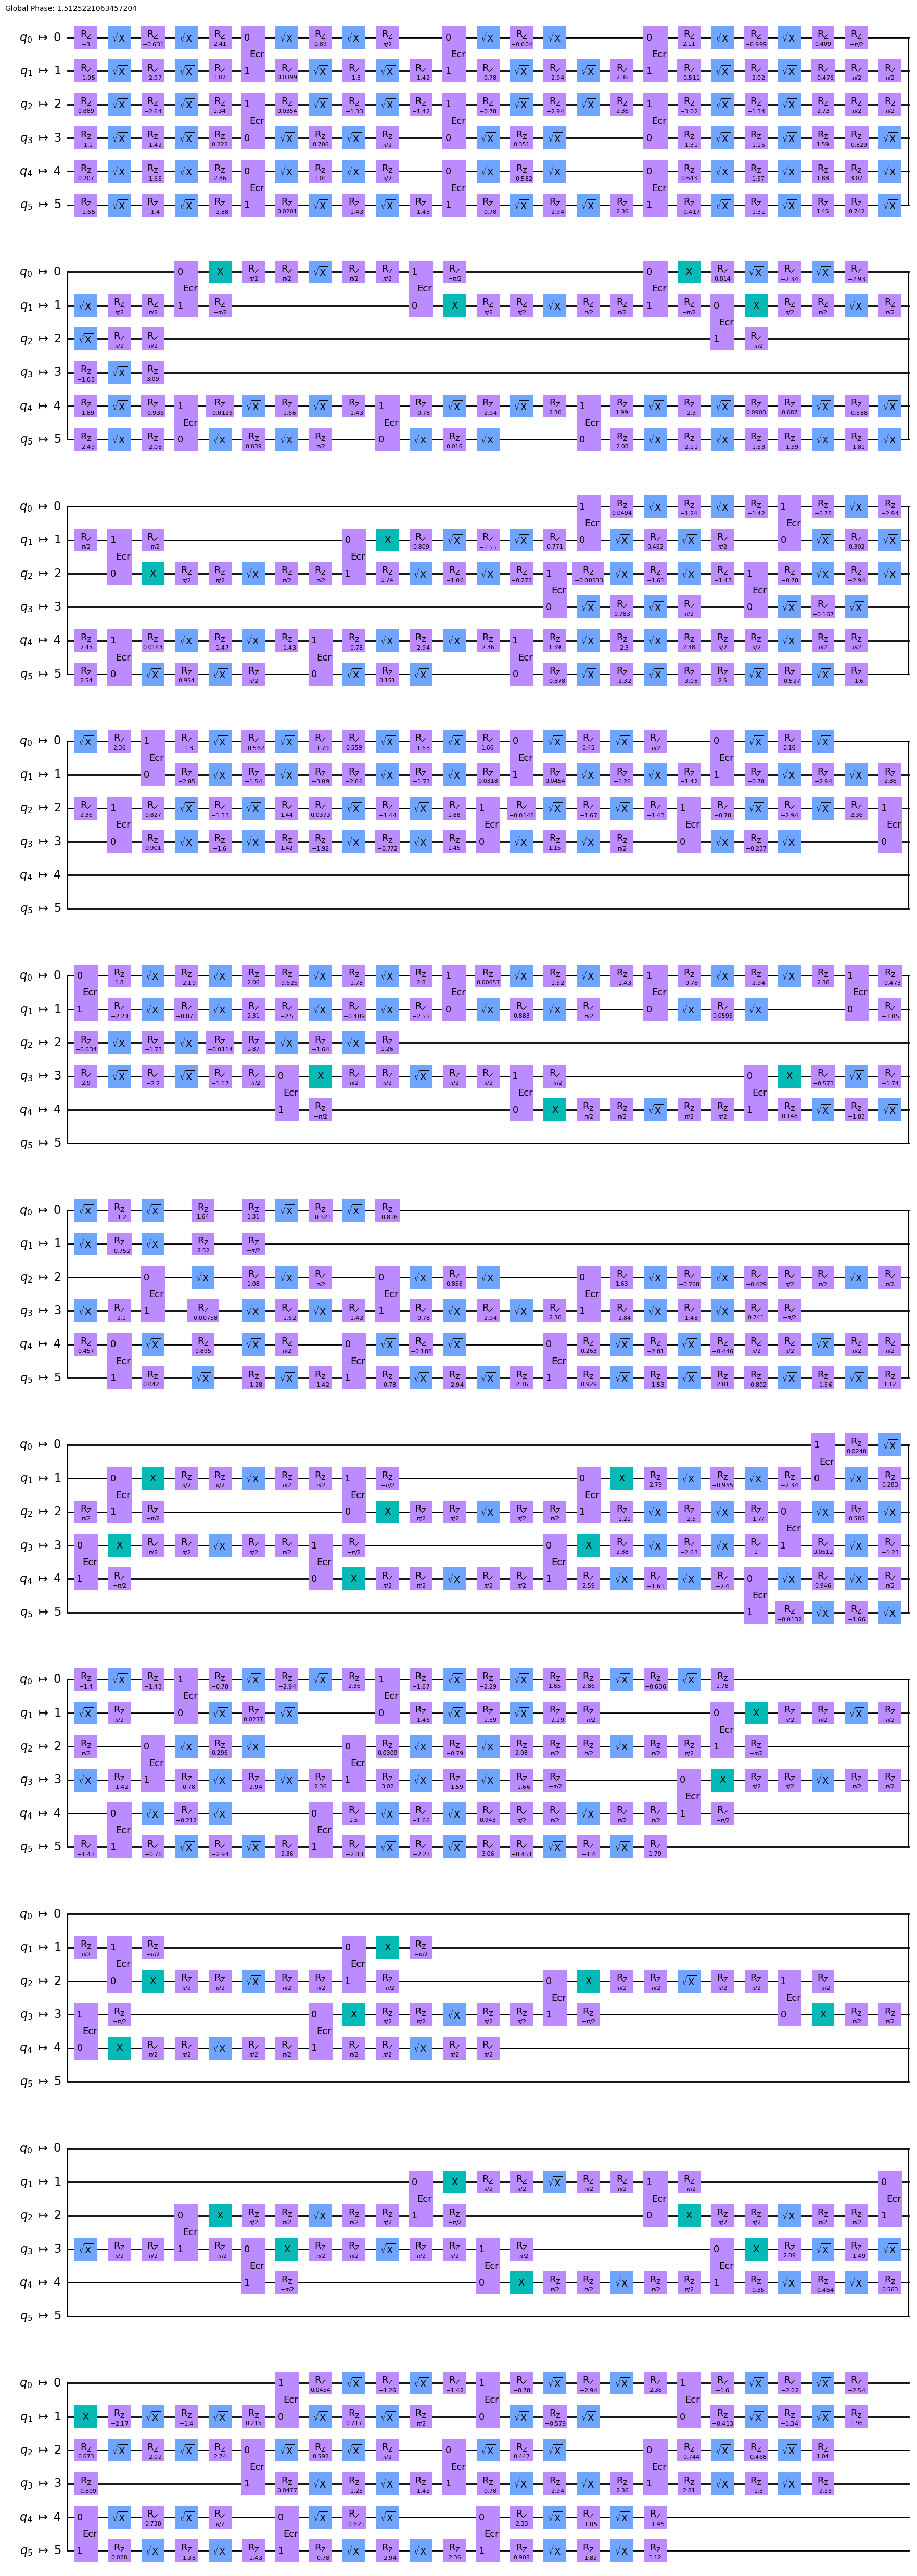

In [2]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap
from qiskit.circuit.library import QuantumVolume

num_qubits = 6
basis_gates = ['ecr','sx','x','rz','id']
qv = QuantumVolume(num_qubits=num_qubits, depth=None, seed=0, classical_permutation=True) 

# This is the default QV
transpiled_qv = transpile(qv, basis_gates=basis_gates)

# ...But we want connectivity taken into account
edge_list = []
for i in range(num_qubits - 1):
    edge_list.append([i, i + 1])
    edge_list.append([i + 1, i])
coupling_map = CouplingMap(edge_list)

optimization_level = 0
transpiled_coupling_qv = transpile(
            qv,
            basis_gates=basis_gates,
            coupling_map=coupling_map,
            seed_transpiler=12345,
            optimization_level=optimization_level,
        )
# ^^^^^ This is where we can plug in a different pass and save the output.

# We would like to see if we can get a denser circuit
transpiled_coupling_qv.draw("mpl")#, fold=-1)